In [21]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import clear_output
from scipy.special import expit


In [22]:
data = np.load("data/a9a_l2_problem.npz")
X = data["X"]
y = data["y"]
L0 = float(data["L0"])
L1 = float(data["L1"])
mu = float(data["mu"])
x_star = data["x_star"]
f_star = float(data["f_star"])
lambda_reg = float(data["lambda_reg"])

print(X.shape, L0, L1, mu, f_star)


(32561, 123) 1.2246956679346566 0.0 0.001 0.526771910574935


In [23]:
delta = 1e-4
K = 4.0
budget = 10_000
start_gap = 3.0
x0_seed = 7
noise_seed = 0
c_R = 1.0
relax_iters = 18
stm_restart_c = 8.0
y_floor = 1e-9


In [24]:
def f(w):
    yz = y * (X @ w)
    return float(np.logaddexp(0.0, -yz).mean() + 0.5 * lambda_reg * float(w @ w))


def grad(w):
    yz = y * (X @ w)
    s = expit(-yz)
    return -(X.T @ (y * s)) / X.shape[0] + lambda_reg * w


class Problem:
    def __init__(self, f, grad, L0, L1, mu, x_star, f_star):
        self.f = f
        self.grad = grad
        self.L0 = L0
        self.L1 = L1
        self.mu = mu
        self.x_star = x_star
        self.f_star = f_star


problem = Problem(f, grad, L0, L1, mu, x_star, f_star)


In [25]:
nu = 0.5
for _ in range(200):
    nu = np.exp(-nu)


def gap_value(prob, x):
    return float(prob.f(x) - prob.f_star)


def pick_start(prob, target, seed):
    rng = np.random.default_rng(seed)
    u = rng.normal(size=prob.x_star.shape)
    u = u / np.linalg.norm(u)
    left, right = 0.0, 20.0
    for _ in range(60):
        middle = 0.5 * (left + right)
        if gap_value(prob, prob.x_star + middle * u) < target:
            left = middle
        else:
            right = middle
    return prob.x_star + 0.5 * (left + right) * u


def random_noise_unit(dim, rng):
    u = rng.normal(size=dim)
    return u / np.linalg.norm(u)


def threshold_alpha(K):
    return 1.0 / (K - 1.0)


def proj_ball(x, center, radius):
    r = x - center
    nr = np.linalg.norm(r)
    if nr <= radius:
        return x
    return center + radius * r / nr


def agmsdr_constants(K, c_R):
    alpha = threshold_alpha(K)
    kappa = (1.0 - alpha) ** 2 / (4.0 * (1.0 + alpha) ** 2)
    C_M = (1.0 + alpha) ** 2 / (2.0 * kappa)
    C_st = 3.0 * C_M / kappa
    c_K = max((16.0 * C_st) ** 0.5, (16.0 * C_st) ** (1.0 / 3.0))
    eps_coef = max((K + 1.0) ** 2 / 2.0, 128.0 * (c_R + 2.0) ** 2)
    return c_K, C_st, eps_coef


In [26]:
def segment_min_beta(v, x, iters=18):
    d = x - v
    Xv = X @ v
    Xd = X @ d
    vd = float(v @ d)
    dd = float(d @ d)

    def dphi(beta):
        yz = y * (Xv + beta * Xd)
        data_der = float(np.mean(-y * Xd * expit(-yz)))
        reg_der = lambda_reg * (vd + beta * dd)
        return data_der + reg_der

    if dphi(0.0) >= 0.0:
        return 0.0
    if dphi(1.0) <= 0.0:
        return 1.0

    left, right = 0.0, 1.0
    for _ in range(iters):
        middle = 0.5 * (left + right)
        if dphi(middle) <= 0.0:
            left = middle
        else:
            right = middle
    return 0.5 * (left + right)


In [27]:
def run_clipped_gd(prob, x0, delta, K, noise_seed, budget):
    rng = np.random.default_rng(noise_seed)
    alpha = threshold_alpha(K)
    x = x0.copy()
    gaps = [gap_value(prob, x)]
    marker_call = None
    marker_gap = None

    for k in range(budget):
        gt = prob.grad(x) + delta * random_noise_unit(x.size, rng)
        ngt = np.linalg.norm(gt)
        if marker_call is None and ngt <= K * delta:
            marker_call = k + 1
            marker_gap = gaps[-1]
        h = 1.0 / (2.0 * (1.0 + alpha))
        h = h / (prob.L0 + prob.L1 * ngt / (1.0 - alpha))
        x = x - h * gt
        gaps.append(gap_value(prob, x))

    return {"gaps": np.asarray(gaps), "marker_call": marker_call, "marker_gap": marker_gap}


def run_restart_stm(prob, x0, delta, K, noise_seed, budget, c=8.0):
    rng = np.random.default_rng(noise_seed)
    eta = nu / 2.0
    Ns = int(np.ceil(c * np.sqrt(prob.L0 / prob.mu)))
    yk = x0.copy()
    gaps = [gap_value(prob, yk)]
    calls = 0
    marker_call = None
    marker_gap = None

    while calls < budget:
        zk = yk.copy()
        A = 0.0
        G = prob.L0
        for k in range(min(Ns, budget - calls)):
            a = eta * (k + 2) / 2.0
            A_next = A + a
            xk = (A * yk + a * zk) / A_next
            gt = prob.grad(xk) + delta * random_noise_unit(xk.size, rng)
            ngt = np.linalg.norm(gt)
            calls += 1
            if marker_call is None and ngt <= K * delta:
                marker_call = calls
                marker_gap = gap_value(prob, xk)
            G = max(G, prob.L0 + prob.L1 * ngt)
            zk = zk - a * gt / G
            yk = (A * yk + a * zk) / A_next
            A = A_next
            gaps.append(gap_value(prob, yk))

    return {"gaps": np.asarray(gaps), "marker_call": marker_call, "marker_gap": marker_gap, "Ns": Ns}


In [28]:
def agmsdr_stage(prob, u, Q_center, Q_radius, K, delta, N, rng, calls0, relax_iters, segment_min_beta_fn=segment_min_beta):
    alpha = threshold_alpha(K)
    x = u.copy()
    v = u.copy()
    A = 0.0
    s = np.zeros_like(u)
    gaps = [gap_value(prob, u)]
    marker_call = None
    marker_gap = None

    for k in range(N):
        beta = segment_min_beta_fn(v, x, iters=relax_iters)
        yk = v + beta * (x - v)
        gt = prob.grad(yk) + delta * random_noise_unit(yk.size, rng)
        ngt = np.linalg.norm(gt)
        call = calls0 + k + 1
        if marker_call is None and ngt <= K * delta:
            marker_call = call
            marker_gap = gap_value(prob, yk)

        h = 1.0 / (2.0 * (1.0 + alpha))
        h = h / (prob.L0 + prob.L1 * ngt / (1.0 - alpha))
        x_next = yk - h * gt
        decrease = prob.f(yk) - prob.f(x_next)
        if decrease <= 0.0 or not np.isfinite(decrease):
            decrease = 1e-18

        M = max(ngt ** 2 / (2.0 * decrease), 1e-300)
        a = (1.0 + np.sqrt(1.0 + 4.0 * M * A)) / (2.0 * M)
        A = A + a
        s = s + a * gt
        v = proj_ball(u - s, Q_center, Q_radius)
        x = x_next
        gaps.append(gap_value(prob, x))

    return x, np.asarray(gaps), marker_call, marker_gap


def run_agmsdr(prob, x0, delta, K, c_R, noise_seed, budget, relax_iters=18, segment_min_beta_fn=segment_min_beta):
    rng = np.random.default_rng(noise_seed)
    c_K, _, _ = agmsdr_constants(K, c_R)
    xs = x0.copy()
    gaps = [gap_value(prob, xs)]
    calls = 0
    marker_call = None
    marker_gap = None

    while calls < budget:
        Fs = max(gap_value(prob, xs), 0.0)
        Rs = np.sqrt(2.0 * Fs / prob.mu)
        Ns = int(np.ceil(c_K * (np.sqrt(prob.L0 / prob.mu) + (prob.L1 ** 2 * Fs / prob.mu) ** (1.0 / 3.0))))
        Ns = max(2, min(Ns, budget - calls))
        xs, stage_gaps, mc, mg = agmsdr_stage(
            prob, xs, xs, c_R * Rs, K, delta, Ns, rng, calls, relax_iters, segment_min_beta_fn
        )
        gaps.extend(stage_gaps[1:].tolist())
        calls += len(stage_gaps) - 1
        if marker_call is None and mc is not None:
            marker_call = mc
            marker_gap = mg

    return {"gaps": np.asarray(gaps[:budget + 1]), "marker_call": marker_call, "marker_gap": marker_gap, "c_K": c_K}


In [29]:
x0 = pick_start(problem, start_gap, x0_seed)
F0 = gap_value(problem, x0)
c_K, C_st, eps_coef = agmsdr_constants(K, c_R)

print(f"a9a: n,d={X.shape}, L0={L0:.4f}, L1={L1:.4f}, mu={mu:.3e}, L0/mu={L0 / mu:.0f}")
print(f"F0={F0:.3f}, delta={delta:g}, K={K:g}, budget={budget}")
print(f"AGMsDR c_K={c_K:.3f}, C_st={C_st:.1f}, floor coefficient={eps_coef:.0f}")

agmsdr = run_agmsdr(problem, x0, delta, K, c_R, noise_seed, budget, relax_iters)
restart_stm = run_restart_stm(problem, x0, delta, K, noise_seed, budget, stm_restart_c)
clipped_gd = run_clipped_gd(problem, x0, delta, K, noise_seed, budget)

print("Projected Restarted AGMsDR marker:", agmsdr["marker_call"])
print("Restarted STM marker:", restart_stm["marker_call"])
print("Clipped-GD marker:", clipped_gd["marker_call"])


a9a: n,d=(32561, 123), L0=1.2247, L1=0.0000, mu=1.000e-03, L0/mu=1225
F0=3.000, delta=0.0001, K=4, budget=10000
AGMsDR c_K=104.512, C_st=682.7, floor coefficient=1152
Projected Restarted AGMsDR marker: 165
Restarted STM marker: 360
Clipped-GD marker: 9005


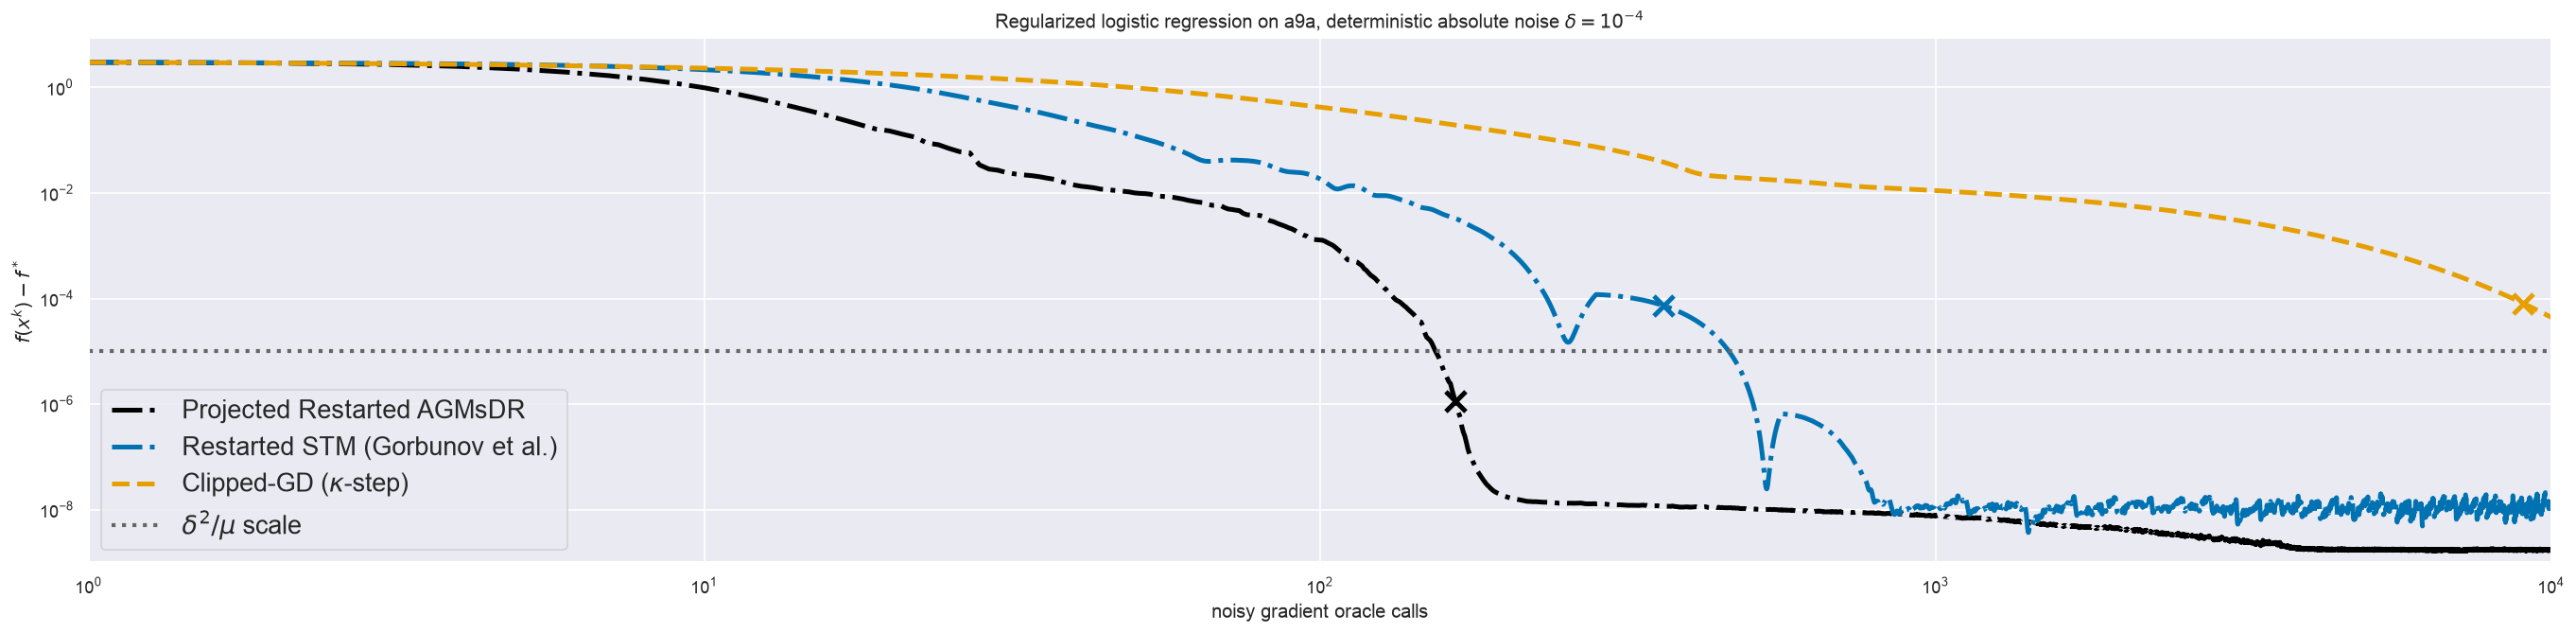

In [30]:
def draw_trace(x, trace, color, linestyle, label):
    gaps = np.maximum(trace["gaps"][:len(x)], y_floor)
    plt.plot(x[:len(gaps)], gaps, color=color, linestyle=linestyle, linewidth=3.0, label=label)
    if trace["marker_call"] is not None:
        marker_x = trace["marker_call"] + 1
        marker_y = max(trace["marker_gap"], y_floor)
        plt.scatter([marker_x], [marker_y], marker="x", color=color, s=160, linewidths=3.0, zorder=10)


x = np.arange(budget + 1) + 1

clear_output(wait=True)
with sns.plotting_context("notebook"), sns.axes_style("darkgrid"):
    plt.figure(figsize=(28, 6), dpi=120)
    draw_trace(x, agmsdr, "black", "-.", "Projected Restarted AGMsDR")
    draw_trace(x, restart_stm, "#0072B2", "-.", "Restarted STM (Gorbunov et al.)")
    draw_trace(x, clipped_gd, "#E69F00", "--", r"Clipped-GD ($\kappa$-step)")
    plt.axhline(delta ** 2 / mu, color="#666666", linestyle=":", linewidth=2.5, label=r"$\delta^2/\mu$ scale")
    plt.title(r"Regularized logistic regression on a9a, deterministic absolute noise $\delta=10^{-4}$")
    plt.xlabel("noisy gradient oracle calls")
    plt.ylabel(r"$f(x^k)-f^*$")
    plt.xscale("log")
    plt.yscale("log")
    plt.xlim(1, budget + 1)
    plt.ylim(bottom=y_floor)
    plt.legend(fontsize=16, loc="lower left")
    plt.show()


In [31]:
quartic_data = np.load("data/a9a_quartic_problem.npz")
X_q = quartic_data["X"]
y_q = quartic_data["y"]
L0_q = float(quartic_data["L0"])
L1_q = float(quartic_data["L1"])
mu_q = float(quartic_data["mu"])
x_star_q = quartic_data["x_star"]
f_star_q = float(quartic_data["f_star"])
lambda_reg_q = float(quartic_data["lambda_reg"])


def f_quartic_a9a(w):
    yz = y_q * (X_q @ w)
    return float(np.logaddexp(0.0, -yz).mean() + lambda_reg_q * float(np.linalg.norm(w) ** 4))


def grad_quartic_a9a(w):
    yz = y_q * (X_q @ w)
    s = expit(-yz)
    nw = np.linalg.norm(w)
    return -(X_q.T @ (y_q * s)) / X_q.shape[0] + 4.0 * lambda_reg_q * (nw ** 2) * w


def segment_min_beta_quartic(v, x, iters=18):
    d = x - v
    Xv = X_q @ v
    Xd = X_q @ d

    def dphi(beta):
        point = v + beta * d
        yz = y_q * (Xv + beta * Xd)
        data_der = float(np.mean(-y_q * Xd * expit(-yz)))
        reg_der = 4.0 * lambda_reg_q * float(point @ point) * float(point @ d)
        return data_der + reg_der

    if dphi(0.0) >= 0.0:
        return 0.0
    if dphi(1.0) <= 0.0:
        return 1.0

    left, right = 0.0, 1.0
    for _ in range(iters):
        middle = 0.5 * (left + right)
        if dphi(middle) <= 0.0:
            left = middle
        else:
            right = middle
    return 0.5 * (left + right)


problem_q = Problem(f_quartic_a9a, grad_quartic_a9a, L0_q, L1_q, mu_q, x_star_q, f_star_q)
x0_q = pick_start(problem_q, start_gap, x0_seed)
F0_q = gap_value(problem_q, x0_q)
c_K_q, C_st_q, eps_coef_q = agmsdr_constants(K, c_R)

print(f"a9a quartic: n,d={X_q.shape}, L0={L0_q:.4f}, L1={L1_q:.4f}, mu={mu_q:.3e}, L0/mu={L0_q / mu_q:.0f}")
print(f"F0={F0_q:.3f}, delta={delta:g}, K={K:g}, budget={budget}")
print(f"AGMsDR c_K={c_K_q:.3f}, C_st={C_st_q:.1f}, floor coefficient={eps_coef_q:.0f}")

agmsdr_q = run_agmsdr(problem_q, x0_q, delta, K, c_R, noise_seed, budget, relax_iters, segment_min_beta_quartic)
restart_stm_q = run_restart_stm(problem_q, x0_q, delta, K, noise_seed, budget, stm_restart_c)
clipped_gd_q = run_clipped_gd(problem_q, x0_q, delta, K, noise_seed, budget)

print("Projected Restarted AGMsDR marker:", agmsdr_q["marker_call"])
print("Restarted STM marker:", restart_stm_q["marker_call"])
print("Clipped-GD marker:", clipped_gd_q["marker_call"])


a9a quartic: n,d=(32561, 123), L0=1.2237, L1=0.1186, mu=3.229e-03, L0/mu=379
F0=3.000, delta=0.0001, K=4, budget=10000
AGMsDR c_K=104.512, C_st=682.7, floor coefficient=1152
Projected Restarted AGMsDR marker: 77
Restarted STM marker: 166
Clipped-GD marker: 1973


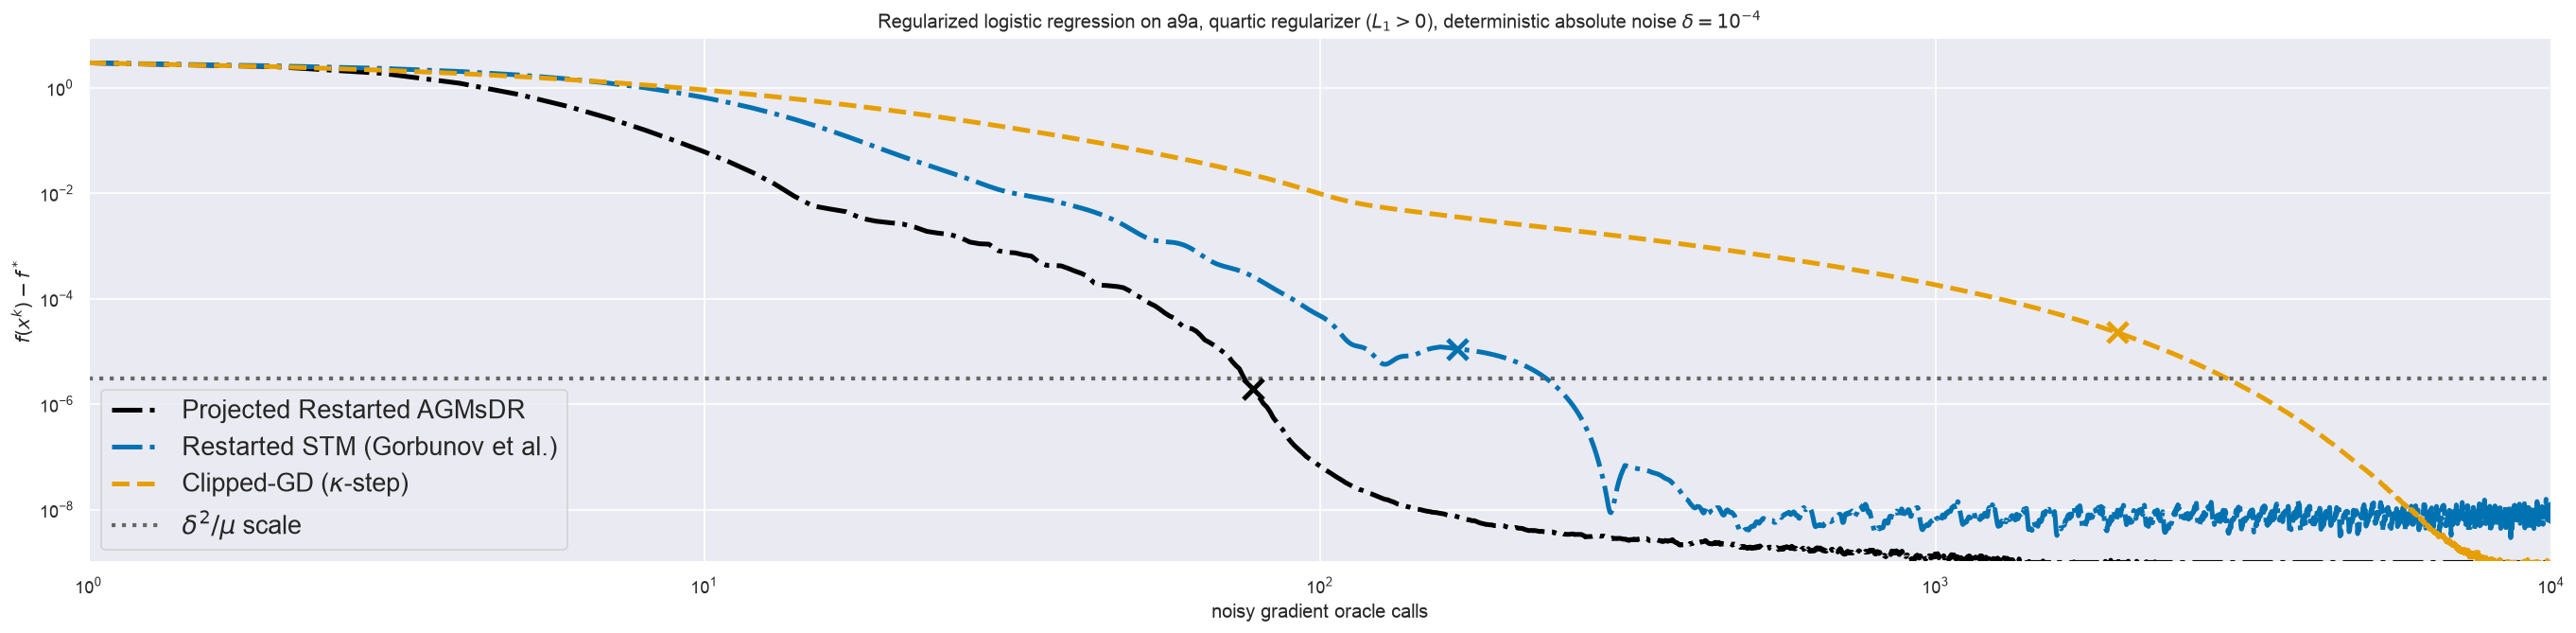

In [ ]:
x = np.arange(budget + 1) + 1

with sns.plotting_context("notebook"), sns.axes_style("darkgrid"):
    plt.figure(figsize=(28, 6), dpi=120)
    draw_trace(x, agmsdr_q, "black", "-.", "Projected Restarted AGMsDR")
    draw_trace(x, restart_stm_q, "#0072B2", "-.", "Restarted STM (Gorbunov et al.)")
    draw_trace(x, clipped_gd_q, "#E69F00", "--", r"Clipped-GD ($\kappa$-step)")
    plt.axhline(delta ** 2 / problem_q.mu, color="#666666", linestyle=":", linewidth=2.5, label=r"$\delta^2/\mu$ scale")
    plt.title(r"Regularized logistic regression on a9a, quartic regularizer ($L_1>0$), deterministic absolute noise $\delta=10^{-4}$")
    plt.xlabel("noisy gradient oracle calls")
    plt.ylabel(r"$f(x^k)-f^*$")
    plt.xscale("log")
    plt.yscale("log")
    plt.xlim(1, budget + 1)
    plt.ylim(bottom=y_floor)
    plt.legend(fontsize=16, loc="lower left")
    plt.show()


In [ ]:
# Appendix G.2 synthetic figures

def kappa(alpha):
    return (1.0 - alpha) ** 2 / (4.0 * (1.0 + alpha) ** 2)


def make_sc_cosh(d=50, kappa_cond=100.0, seed=0):
    rng = np.random.default_rng(seed)
    sigma = np.exp(np.linspace(0.0, 0.5 * np.log(kappa_cond), d))
    rng.shuffle(sigma)

    def f_cosh(x):
        return float(np.sum(np.cosh(sigma * x)))

    def grad_cosh(x):
        return sigma * np.sinh(sigma * x)

    return Problem(
        f_cosh,
        grad_cosh,
        float(np.max(sigma) ** 2),
        float(np.max(sigma)),
        float(np.min(sigma) ** 2),
        np.zeros(d),
        float(d),
    )


def make_cvx_quartic(d=50, L1=1.0, seed=1):
    rng = np.random.default_rng(seed)
    b = rng.uniform(-1.0, 1.0, size=d)

    def f_quartic(x):
        return float(0.25 * np.sum(x ** 4) - b @ x)

    def grad_quartic(x):
        return x ** 3 - b

    x_star = np.cbrt(b)
    f_star = f_quartic(x_star)
    return Problem(f_quartic, grad_quartic, 4.0 / L1 ** 2, L1, 0.0, x_star, f_star)


def random_unit_sequence(count, dim, seed):
    rng = np.random.default_rng(seed)
    U = rng.normal(size=(count, dim))
    norms = np.linalg.norm(U, axis=1)
    zero = norms == 0.0
    if np.any(zero):
        U[zero, 0] = 1.0
        norms[zero] = 1.0
    return U / norms[:, None]


def perp_unit(g):
    d = g.shape[0]
    e = np.zeros(d)
    e[0] = 1.0
    ng = np.linalg.norm(g)
    if ng == 0.0:
        return e
    if abs(g[0]) > 0.9 * ng:
        e[:] = 0.0
        e[1 % d] = 1.0
    gh = g / ng
    p = e - (e @ gh) * gh
    np_ = np.linalg.norm(p)
    return p / np_ if np_ > 1e-12 else e


def oracle_relative_adv(g, alpha):
    ng = np.linalg.norm(g)
    if ng == 0.0 or alpha == 0.0:
        return g.copy()
    gh = g / ng
    p = perp_unit(g)
    return ng * ((1.0 - alpha ** 2) * gh + alpha * np.sqrt(1.0 - alpha ** 2) * p)


def oracle_relative_dir(g, alpha, direction):
    ng = np.linalg.norm(g)
    if ng == 0.0 or alpha == 0.0:
        return g.copy()
    return g + alpha * ng * direction


def oracle_composite_dirs(g, alpha, delta, rel_direction, abs_direction):
    gt = oracle_relative_dir(g, alpha, rel_direction)
    if delta == 0.0:
        return gt
    return gt + delta * abs_direction


def oracle_absolute_dir(g, delta, direction):
    return g + delta * direction


In [ ]:
def synthetic_clipped_gd(prob, x0, oracle, N, alpha):
    x = x0.copy()
    gaps = []
    gnorms = []
    for k in range(N):
        g = prob.grad(x)
        gt = oracle(g, k)
        ngt = np.linalg.norm(gt)
        gaps.append(prob.f(x) - prob.f_star)
        gnorms.append(np.linalg.norm(g))
        if ngt == 0.0:
            break
        h = 1.0 / (2.0 * (1.0 + alpha))
        h = h / (prob.L0 + prob.L1 * ngt / (1.0 - alpha))
        x = x - h * gt
    gaps.append(prob.f(x) - prob.f_star)
    gnorms.append(np.linalg.norm(prob.grad(x)))
    return np.asarray(gaps), np.asarray(gnorms), x


def synthetic_thresholded_clipped_gd(prob, x0, oracle, N, alpha, delta, K, pad_to=None):
    alpha_hat = alpha + (1.0 + alpha) / (K - 1.0)
    x = x0.copy()
    gaps = []
    for k in range(N):
        g = prob.grad(x)
        gt = oracle(g, k)
        ngt = np.linalg.norm(gt)
        gaps.append(prob.f(x) - prob.f_star)
        if ngt <= K * delta:
            break
        h = 1.0 / (2.0 * (1.0 + alpha_hat))
        h = h / (prob.L0 + prob.L1 * ngt / (1.0 - alpha_hat))
        x = x - h * gt
    gaps.append(prob.f(x) - prob.f_star)
    if pad_to is not None and len(gaps) < pad_to:
        gaps = gaps + [gaps[-1]] * (pad_to - len(gaps))
    return np.asarray(gaps), x


def const_step_gd(prob, x0, oracle, N, G):
    x = x0.copy()
    h = 1.0 / (prob.L0 + prob.L1 * G)
    gaps = []
    for k in range(N):
        gt = oracle(prob.grad(x), k)
        gaps.append(prob.f(x) - prob.f_star)
        x = x - h * gt
    gaps.append(prob.f(x) - prob.f_star)
    return np.asarray(gaps), x


def gd_one_over_L0(prob, x0, oracle, N):
    x = x0.copy()
    h = 1.0 / prob.L0
    gaps = []
    for k in range(N):
        gt = oracle(prob.grad(x), k)
        gaps.append(prob.f(x) - prob.f_star)
        x = x - h * gt
        if not np.isfinite(prob.f(x)):
            gaps.extend([np.nan] * (N - k))
            break
    gaps.append(prob.f(x) - prob.f_star)
    return np.asarray(gaps[:N + 1]), x


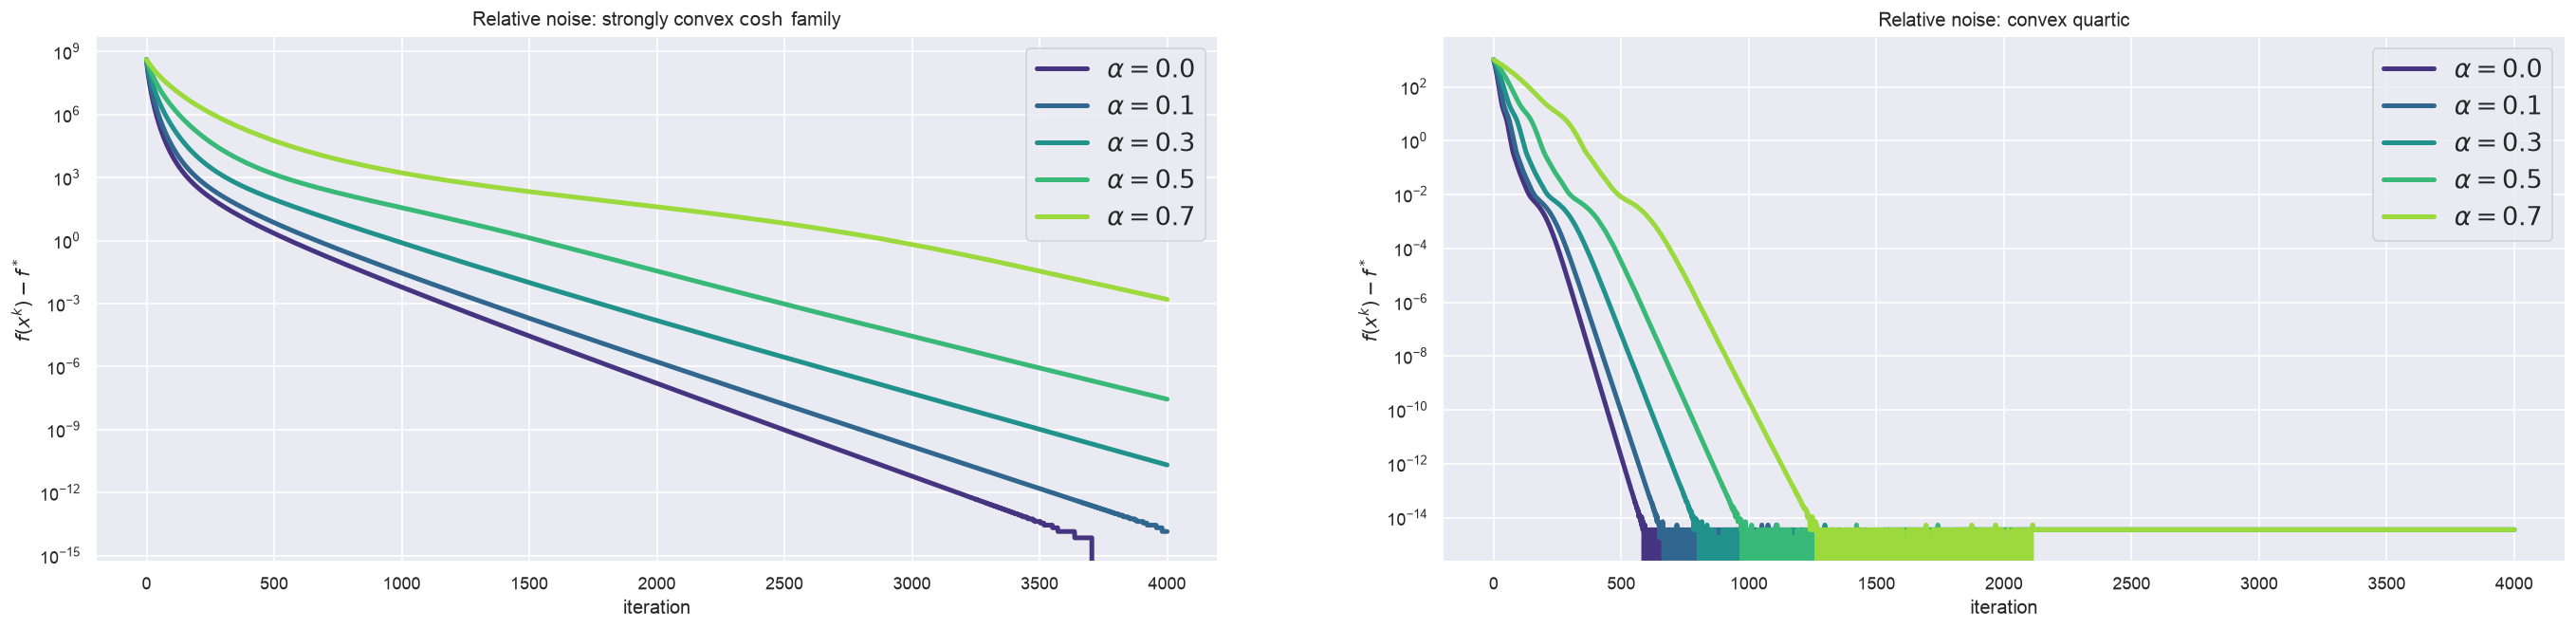

In [ ]:
# E1: relative noise, varying alpha
alphas = [0.0, 0.1, 0.3, 0.5, 0.7]
colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(alphas)))
N = 4000

with sns.plotting_context("notebook"), sns.axes_style("darkgrid"):
    plt.figure(figsize=(28, 6), dpi=120)

    plt.subplot(1, 2, 1)
    prob_sc = make_sc_cosh(d=50, kappa_cond=100.0)
    x0_sc = np.full(50, 2.0)
    dirs = random_unit_sequence(N + 1, 50, 101)
    for alpha, color in zip(alphas, colors):
        oracle = lambda g, k, alpha=alpha, dirs=dirs: oracle_relative_dir(g, alpha, dirs[k])
        gaps, _, _ = synthetic_clipped_gd(prob_sc, x0_sc, oracle, N, alpha)
        plt.semilogy(gaps, color=color, linewidth=3.0, label=fr"$\alpha={alpha}$")
    plt.title(r"Relative noise: strongly convex $\cosh$ family")
    plt.xlabel("iteration")
    plt.ylabel(r"$f(x^k)-f^*$")
    plt.legend(fontsize=16)

    plt.subplot(1, 2, 2)
    prob_cvx = make_cvx_quartic(d=50, L1=1.0)
    x0_cvx = np.full(50, 3.0)
    dirs = random_unit_sequence(N + 1, 50, 102)
    for alpha, color in zip(alphas, colors):
        oracle = lambda g, k, alpha=alpha, dirs=dirs: oracle_relative_dir(g, alpha, dirs[k])
        gaps, _, _ = synthetic_clipped_gd(prob_cvx, x0_cvx, oracle, N, alpha)
        plt.semilogy(gaps, color=color, linewidth=3.0, label=fr"$\alpha={alpha}$")
    plt.title(r"Relative noise: convex quartic")
    plt.xlabel("iteration")
    plt.ylabel(r"$f(x^k)-f^*$")
    plt.legend(fontsize=16)

    plt.show()


/var/folders/l6/xrp03sqs51d0_4nd41zr6tkc0000gn/T/ipykernel_32292/3896117079.py:13: RuntimeWarning: overflow encountered in cosh
  return float(np.sum(np.cosh(sigma * x)))


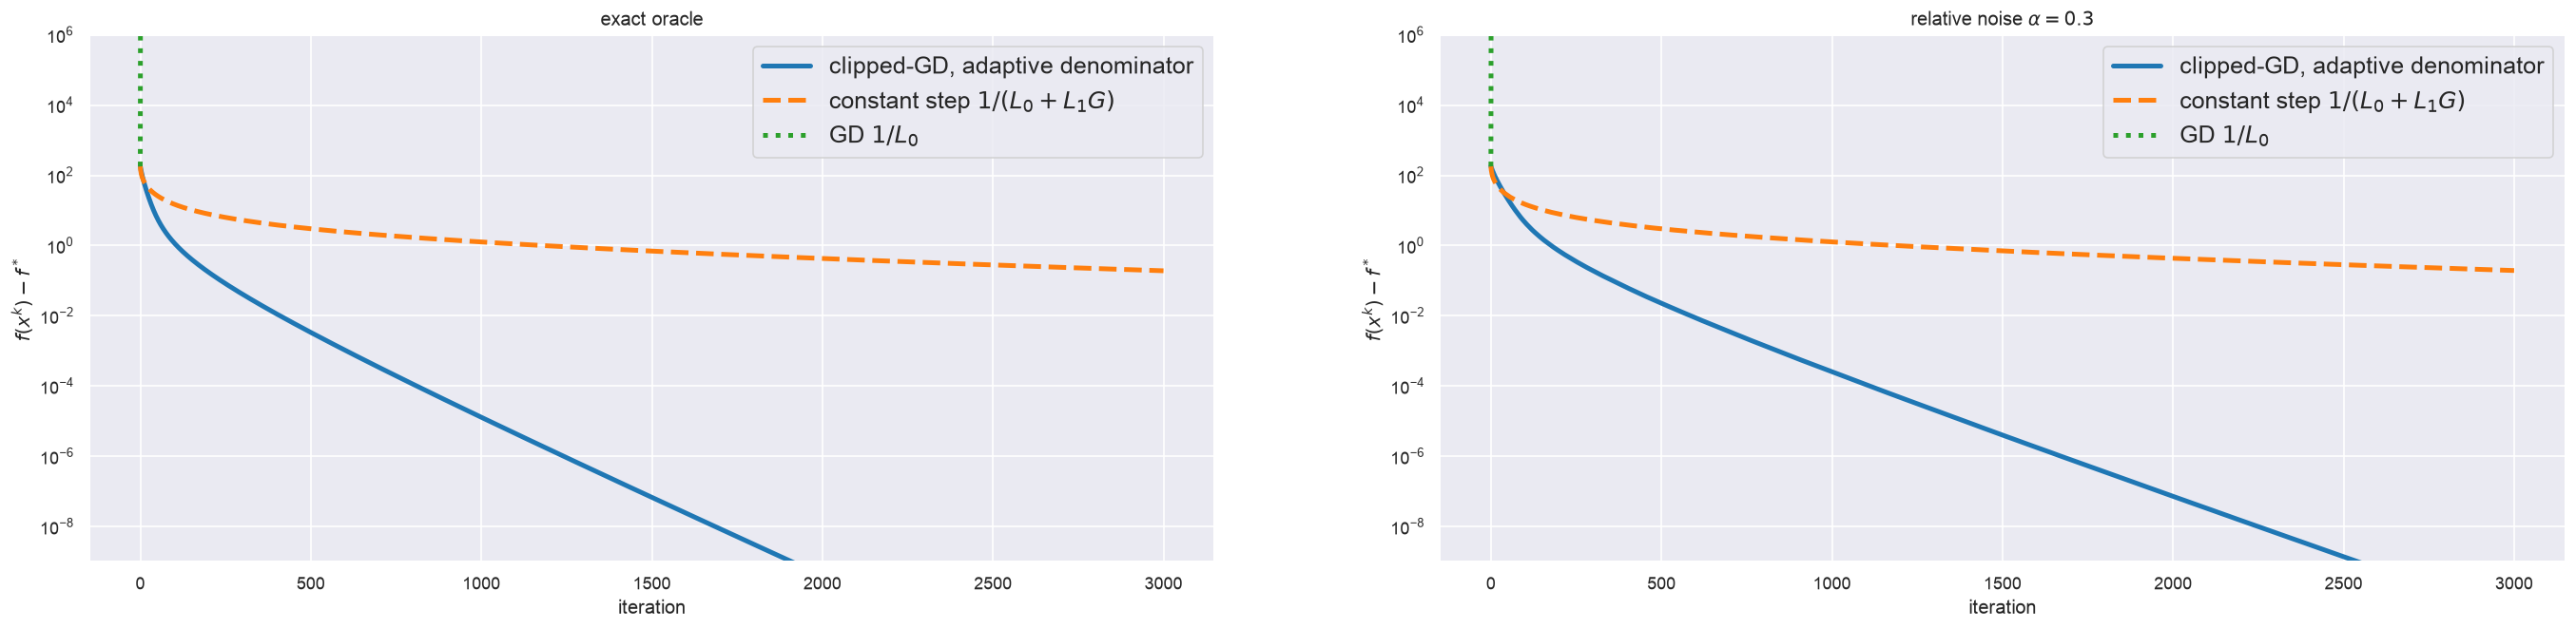

In [ ]:
# E2: native denominator against surrogate-L baselines
prob = make_sc_cosh(d=50, kappa_cond=100.0)
x0 = np.full(50, 0.4)
N = 3000
G = np.linalg.norm(prob.grad(x0))

with sns.plotting_context("notebook"), sns.axes_style("darkgrid"):
    plt.figure(figsize=(28, 6), dpi=120)
    for j, (alpha, title) in enumerate([(0.0, r"exact oracle"), (0.3, r"relative noise $\alpha=0.3$")], start=1):
        dirs = random_unit_sequence(N + 1, 50, 200 + j)
        oracle = lambda g, k, alpha=alpha, dirs=dirs: oracle_relative_dir(g, alpha, dirs[k])
        gaps_native, _, _ = synthetic_clipped_gd(prob, x0, oracle, N, alpha)
        gaps_const, _ = const_step_gd(prob, x0, oracle, N, G)
        gaps_l0, _ = gd_one_over_L0(prob, x0, oracle, N)

        plt.subplot(1, 2, j)
        plt.semilogy(gaps_native, linewidth=3.0, label=r"clipped-GD, adaptive denominator")
        plt.semilogy(gaps_const, "--", linewidth=3.0, label=r"constant step $1/(L_0+L_1G)$")
        plt.semilogy(gaps_l0, ":", linewidth=3.0, label=r"GD $1/L_0$")
        plt.title(title)
        plt.xlabel("iteration")
        plt.ylabel(r"$f(x^k)-f^*$")
        plt.ylim(1e-9, 1e6)
        plt.legend(fontsize=15)
    plt.show()


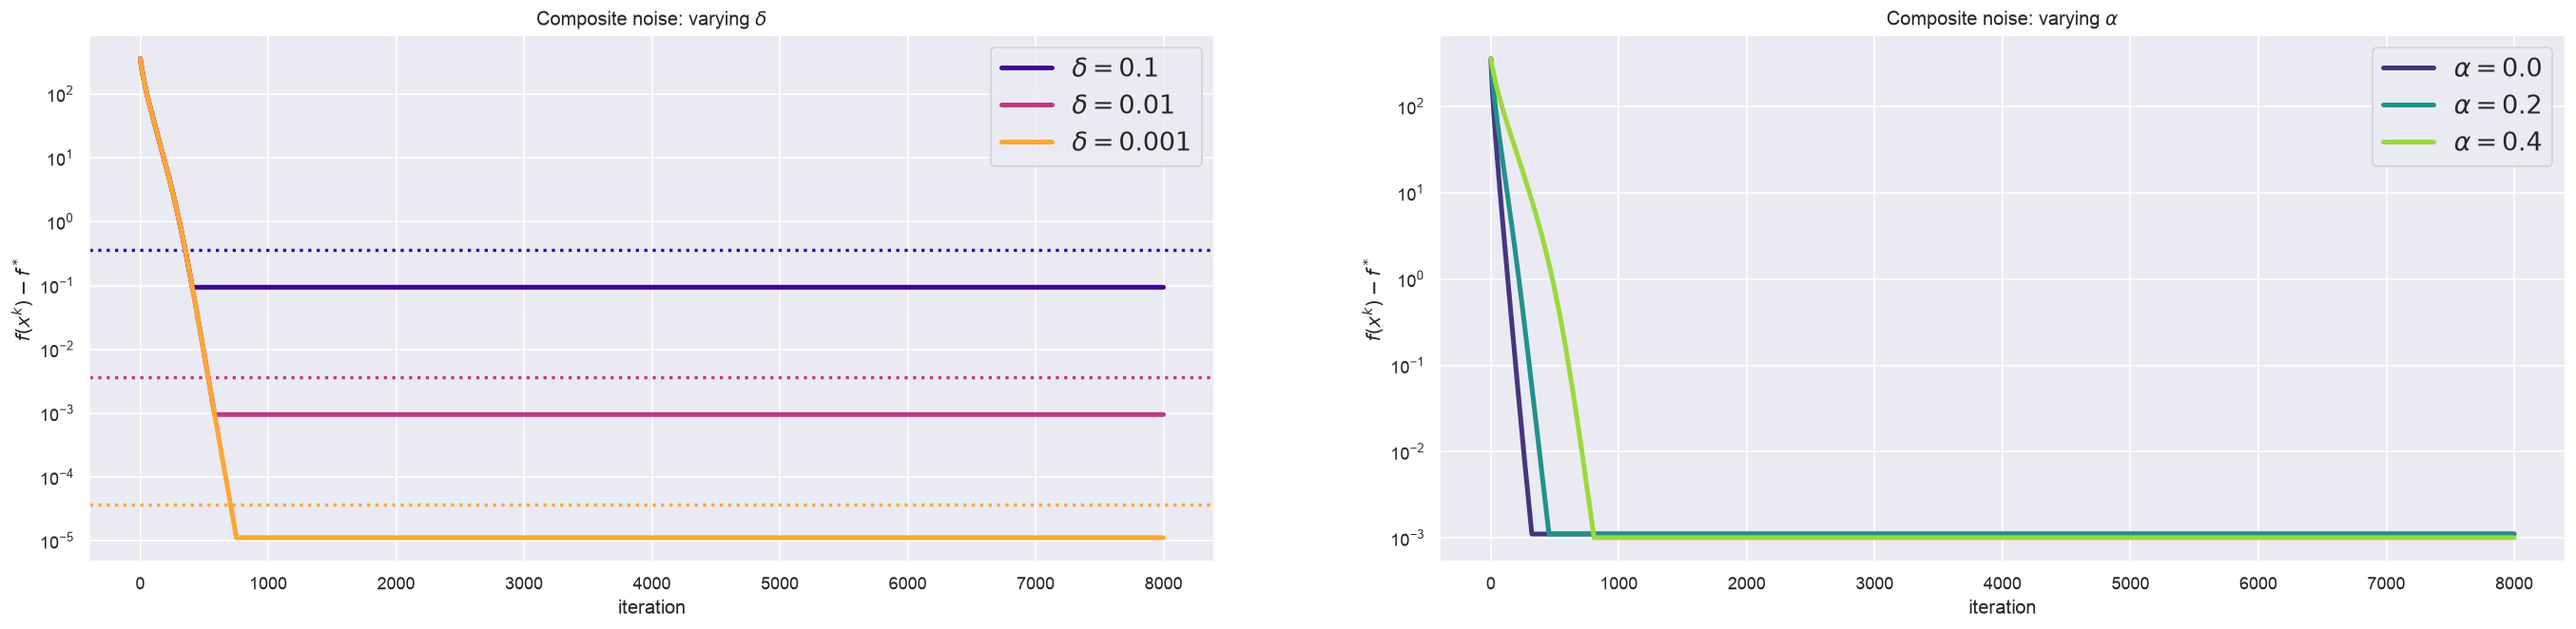

In [ ]:
# E3: composite noise and the threshold floor
K_comp = 5.0
N = 8000
prob = make_sc_cosh(d=30, kappa_cond=25.0)
x0 = np.full(30, 1.0)

with sns.plotting_context("notebook"), sns.axes_style("darkgrid"):
    plt.figure(figsize=(28, 6), dpi=120)

    plt.subplot(1, 2, 1)
    alpha = 0.3
    deltas = [1e-1, 1e-2, 1e-3]
    colors = plt.cm.plasma(np.linspace(0.1, 0.8, len(deltas)))
    rel_dirs = random_unit_sequence(N + 1, 30, 301)
    abs_dirs = random_unit_sequence(N + 1, 30, 302)
    for delta_i, color in zip(deltas, colors):
        oracle = lambda g, k, alpha=alpha, delta_i=delta_i: oracle_composite_dirs(g, alpha, delta_i, rel_dirs[k], abs_dirs[k])
        gaps, _ = synthetic_thresholded_clipped_gd(prob, x0, oracle, N, alpha, delta_i, K_comp, pad_to=N)
        plt.semilogy(gaps, color=color, linewidth=3.0, label=fr"$\delta={delta_i:g}$")
        floor = (K_comp + 1.0) ** 2 * delta_i ** 2 / (2.0 * prob.mu * (1.0 - alpha) ** 2)
        plt.axhline(floor, color=color, linestyle=":", linewidth=2.0)
    plt.title(r"Composite noise: varying $\delta$")
    plt.xlabel("iteration")
    plt.ylabel(r"$f(x^k)-f^*$")
    plt.legend(fontsize=16)

    plt.subplot(1, 2, 2)
    delta_i = 1e-2
    alphas = [0.0, 0.2, 0.4]
    colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(alphas)))
    rel_dirs = random_unit_sequence(N + 1, 30, 303)
    abs_dirs = random_unit_sequence(N + 1, 30, 304)
    for alpha, color in zip(alphas, colors):
        oracle = lambda g, k, alpha=alpha: oracle_composite_dirs(g, alpha, delta_i, rel_dirs[k], abs_dirs[k])
        gaps, _ = synthetic_thresholded_clipped_gd(prob, x0, oracle, N, alpha, delta_i, K_comp, pad_to=N)
        plt.semilogy(gaps, color=color, linewidth=3.0, label=fr"$\alpha={alpha}$")
    plt.title(r"Composite noise: varying $\alpha$")
    plt.xlabel("iteration")
    plt.ylabel(r"$f(x^k)-f^*$")
    plt.legend(fontsize=16)

    plt.show()


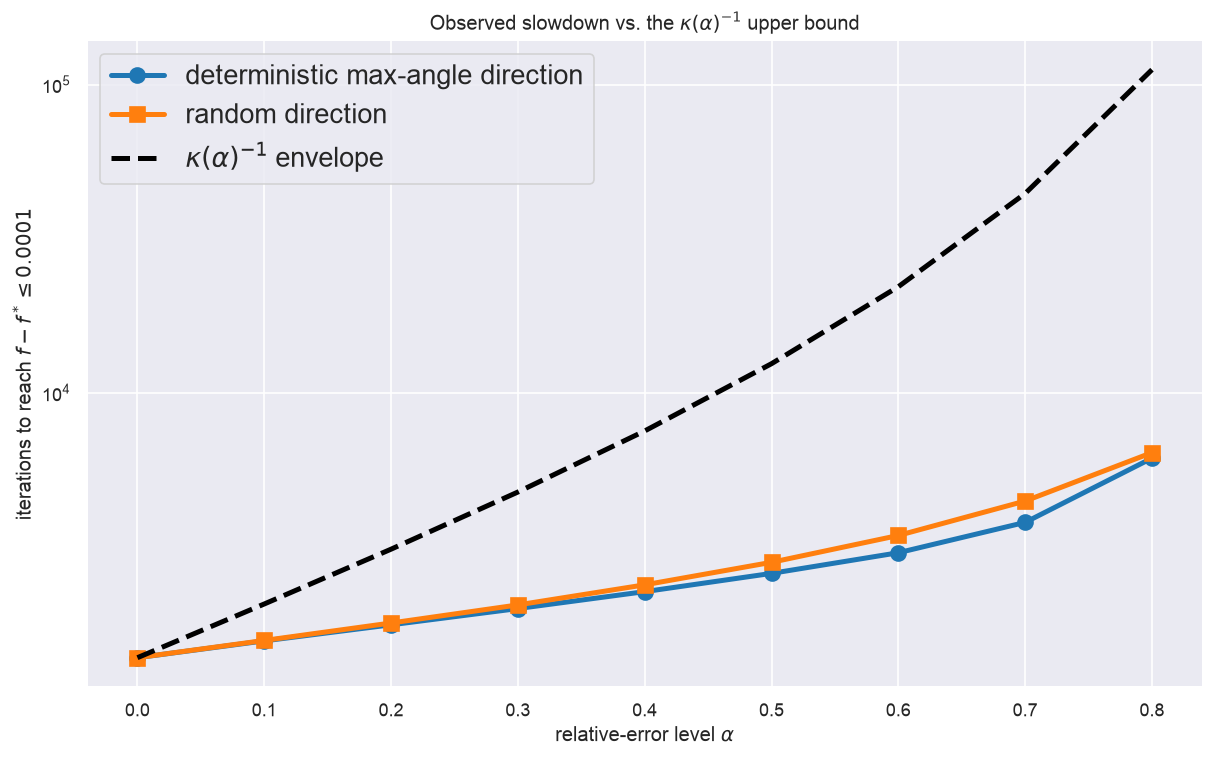

In [ ]:
# E4: observed slowdown against the kappa envelope
prob = make_sc_cosh(d=50, kappa_cond=100.0)
x0 = np.full(50, 2.0)
eps = 1e-4
N = 20000
alphas = np.linspace(0.0, 0.8, 9)
iters_det = []
iters_rand = []

for i, alpha in enumerate(alphas):
    dirs = random_unit_sequence(N + 1, 50, 401 + i)
    oracle_det = lambda g, k, alpha=alpha: oracle_relative_adv(g, alpha)
    oracle_rand = lambda g, k, alpha=alpha, dirs=dirs: oracle_relative_dir(g, alpha, dirs[k])
    gaps_det, _, _ = synthetic_clipped_gd(prob, x0, oracle_det, N, alpha)
    gaps_rand, _, _ = synthetic_clipped_gd(prob, x0, oracle_rand, N, alpha)

    idx = np.where(gaps_det <= eps)[0]
    iters_det.append(idx[0] if len(idx) else np.nan)
    idx = np.where(gaps_rand <= eps)[0]
    iters_rand.append(idx[0] if len(idx) else np.nan)

iters_det = np.asarray(iters_det, dtype=float)
iters_rand = np.asarray(iters_rand, dtype=float)
pred = kappa(0.0) * iters_det[0] / kappa(alphas)

with sns.plotting_context("notebook"), sns.axes_style("darkgrid"):
    plt.figure(figsize=(12, 7), dpi=120)
    plt.semilogy(alphas, iters_det, "o-", linewidth=3.0, markersize=9, label="deterministic max-angle direction")
    plt.semilogy(alphas, iters_rand, "s-", linewidth=3.0, markersize=9, label="random direction")
    plt.semilogy(alphas, pred, "k--", linewidth=3.0, label=r"$\kappa(\alpha)^{-1}$ envelope")
    plt.xlabel(r"relative-error level $\alpha$")
    plt.ylabel(fr"iterations to reach $f-f^*\leq {eps:g}$")
    plt.title(r"Observed slowdown vs. the $\kappa(\alpha)^{-1}$ upper bound")
    plt.legend(fontsize=16)
    plt.show()


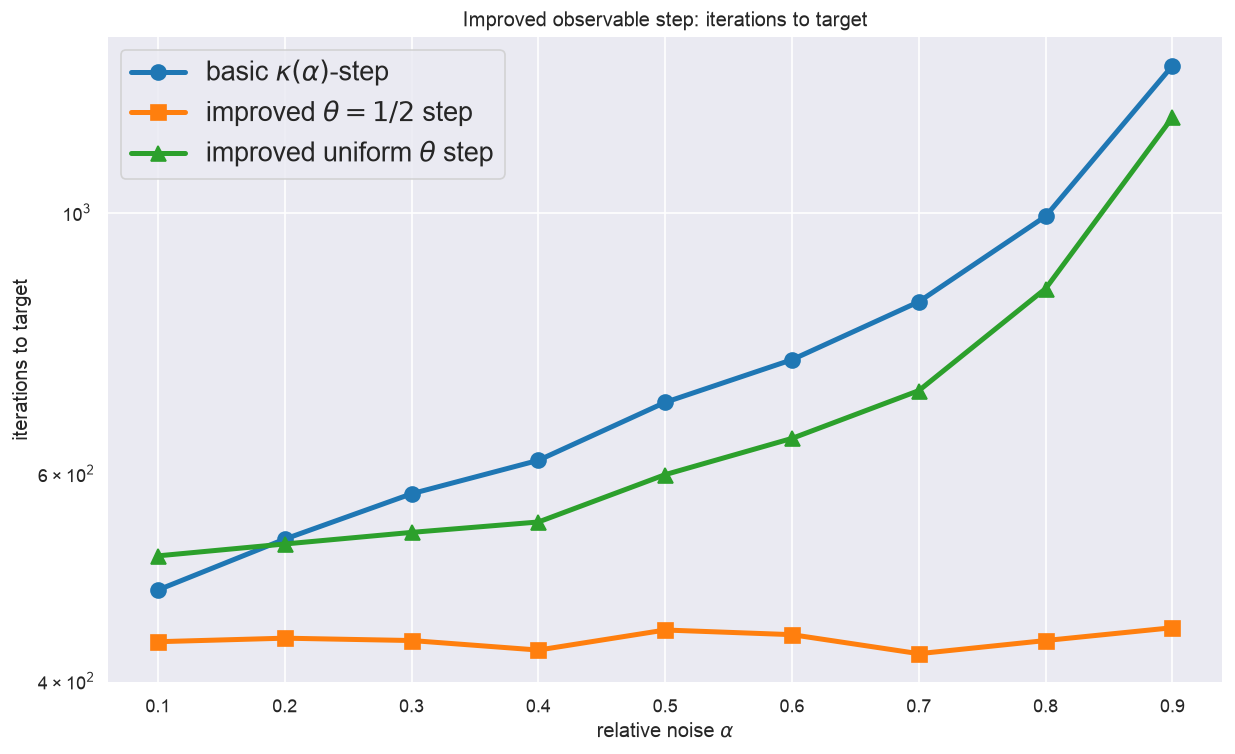

In [ ]:
# Etheta: improved observable step

def theta_uniform(alpha):
    return 2.0 * np.sqrt(1.0 - alpha ** 2) / (np.sqrt(3.0) * np.e)


def clipped_gd_basic_iterations(prob, x0, alpha, N, tol, dirs):
    x = x0.copy()
    for k in range(N):
        if prob.f(x) - prob.f_star <= tol:
            return k
        gt = oracle_relative_dir(prob.grad(x), alpha, dirs[k])
        ngt = np.linalg.norm(gt)
        h = 1.0 / (2.0 * (1.0 + alpha))
        h = h / (prob.L0 + prob.L1 * ngt / (1.0 - alpha))
        x = x - h * gt
    return N


def clipped_gd_theta_iterations(prob, x0, alpha, theta, N, tol, dirs):
    x = x0.copy()
    for k in range(N):
        if prob.f(x) - prob.f_star <= tol:
            return k
        gt = oracle_relative_dir(prob.grad(x), alpha, dirs[k])
        ngt = np.linalg.norm(gt)
        x = x - theta * gt / (prob.L0 + prob.L1 * ngt)
    return N


prob = make_sc_cosh(d=20, kappa_cond=50.0)
x0 = np.full(20, 0.25)
tol = 1e-6 * (prob.f(x0) - prob.f_star)
N = 200000
alphas = np.linspace(0.1, 0.9, 9)
it_basic = []
it_half = []
it_unif = []

for i, alpha in enumerate(alphas):
    dirs = random_unit_sequence(N + 1, 20, 501 + i)
    it_basic.append(clipped_gd_basic_iterations(prob, x0, alpha, N, tol, dirs))
    it_half.append(clipped_gd_theta_iterations(prob, x0, alpha, 0.5, N, tol, dirs))
    it_unif.append(clipped_gd_theta_iterations(prob, x0, alpha, theta_uniform(alpha), N, tol, dirs))

with sns.plotting_context("notebook"), sns.axes_style("darkgrid"):
    plt.figure(figsize=(12, 7), dpi=120)
    plt.semilogy(alphas, it_basic, "o-", linewidth=3.0, markersize=9, label=r"basic $\kappa(\alpha)$-step")
    plt.semilogy(alphas, it_half, "s-", linewidth=3.0, markersize=9, label=r"improved $\theta=1/2$ step")
    plt.semilogy(alphas, it_unif, "^-", linewidth=3.0, markersize=9, label=r"improved uniform $\theta$ step")
    plt.xlabel(r"relative noise $\alpha$")
    plt.ylabel("iterations to target")
    plt.title("Improved observable step: iterations to target")
    plt.legend(fontsize=16)
    plt.show()


In [ ]:
# E5 and E6: accelerated methods
_GR = (np.sqrt(5.0) - 1.0) / 2.0


def golden_min(phi, left=0.0, right=1.0, iters=60):
    c = right - _GR * (right - left)
    d = left + _GR * (right - left)
    fc = phi(c)
    fd = phi(d)
    for _ in range(iters):
        if fc < fd:
            right, d, fd = d, c, fc
            c = right - _GR * (right - left)
            fc = phi(c)
        else:
            left, c, fc = c, d, fd
            d = left + _GR * (right - left)
            fd = phi(d)
    return 0.5 * (left + right)


def a_kornilov(N, alpha):
    return max(36.0, max(1.0, np.sqrt(N) * np.sqrt(alpha), N * alpha, N ** 2 * alpha ** 2))


def istm_block(prob, x0, Lbar, a, alpha, N, dirs, calls0):
    y = x0.copy()
    z = x0.copy()
    A = 0.0
    gaps = [prob.f(y) - prob.f_star]
    for k in range(N):
        a_next = (k + 2) / (2.0 * a * Lbar)
        A_next = A + a_next
        x = (A * y + a_next * z) / A_next
        gt = oracle_relative_dir(prob.grad(x), alpha, dirs[calls0 + k])
        z_new = z - a_next * gt
        y = (A * y + a_next * z_new) / A_next
        z, A = z_new, A_next
        gaps.append(prob.f(y) - prob.f_star)
    return y, np.asarray(gaps)


def two_phase(prob, x0, alpha, eps, dirs, surrogate=32.0):
    x = x0.copy()
    F0 = prob.f(x) - prob.f_star
    gaps = [F0]
    calls = 0
    F_exit = F0 if prob.L1 == 0.0 else min(F0, prob.mu / (8.0 * prob.L1 ** 2))

    while prob.f(x) - prob.f_star > F_exit:
        gt = oracle_relative_dir(prob.grad(x), alpha, dirs[calls])
        ngt = np.linalg.norm(gt)
        h = 1.0 / (2.0 * (1.0 + alpha))
        h = h / (prob.L0 + prob.L1 * ngt / (1.0 - alpha))
        x = x - h * gt
        calls += 1
        gaps.append(prob.f(x) - prob.f_star)

    if eps < F_exit:
        S = int(np.ceil(np.log2(F_exit / eps)))
        Lbar = surrogate * prob.L0
        a = 36.0
        for _ in range(40):
            Ns = int(np.ceil(4.0 * np.sqrt(a) * np.sqrt(Lbar / prob.mu)))
            a_new = a_kornilov(Ns, alpha)
            if abs(a_new - a) < 1e-6:
                a = a_new
                break
            a = a_new
        Ns = int(np.ceil(4.0 * np.sqrt(a) * np.sqrt(Lbar / prob.mu)))
        for _ in range(S):
            x, block_gaps = istm_block(prob, x, Lbar, a, alpha, Ns, dirs, calls)
            calls += len(block_gaps) - 1
            gaps.extend(block_gaps[1:].tolist())
    return np.asarray(gaps)


def clipped_gd_relative_trace(prob, x0, alpha, eps, N, dirs):
    x = x0.copy()
    gaps = [prob.f(x) - prob.f_star]
    for k in range(N):
        if prob.f(x) - prob.f_star <= eps:
            break
        gt = oracle_relative_dir(prob.grad(x), alpha, dirs[k])
        ngt = np.linalg.norm(gt)
        h = 1.0 / (2.0 * (1.0 + alpha))
        h = h / (prob.L0 + prob.L1 * ngt / (1.0 - alpha))
        x = x - h * gt
        gaps.append(prob.f(x) - prob.f_star)
    return np.asarray(gaps)


def native_restart_stm(prob, x0, alpha, eps, dirs, c=8.0, maxcalls=4_000_000):
    eta = nu / 2.0
    Ns = int(np.ceil(c * np.sqrt(prob.L0 / prob.mu)))
    yk = x0.copy()
    gaps = [prob.f(yk) - prob.f_star]
    calls = 0
    maxR = 0.0
    while gaps[-1] > eps and calls < maxcalls:
        zk = yk.copy()
        A = 0.0
        G = prob.L0
        R0 = np.linalg.norm(zk - prob.x_star) + 1e-30
        for k in range(Ns):
            if calls >= maxcalls:
                break
            a_next = eta * (k + 2) / 2.0
            A_next = A + a_next
            xk = (A * yk + a_next * zk) / A_next
            gt = oracle_relative_dir(prob.grad(xk), alpha, dirs[calls])
            G = max(G, prob.L0 + prob.L1 * np.linalg.norm(gt))
            zk = zk - a_next * gt / G
            yk = (A * yk + a_next * zk) / A_next
            A = A_next
            calls += 1
            gaps.append(prob.f(yk) - prob.f_star)
            maxR = max(maxR, np.linalg.norm(zk - prob.x_star) / R0)
    return np.asarray(gaps), calls, Ns, maxR


def synthetic_agmsdr_stage(prob, u, Q_center, Q_radius, K, delta, N, dirs, calls0):
    alpha = threshold_alpha(K)
    x = u.copy()
    v = u.copy()
    A = 0.0
    s = np.zeros_like(u)
    gaps = [prob.f(u) - prob.f_star]
    stopped = False
    for k in range(N):
        call = calls0 + k
        beta = golden_min(lambda b: prob.f(v + b * (x - v)))
        yk = v + beta * (x - v)
        gt = oracle_absolute_dir(prob.grad(yk), delta, dirs[call])
        ngt = np.linalg.norm(gt)
        if ngt <= K * delta:
            gaps.append(prob.f(yk) - prob.f_star)
            return yk, np.asarray(gaps), True
        h = 1.0 / (2.0 * (1.0 + alpha))
        h = h / (prob.L0 + prob.L1 * ngt / (1.0 - alpha))
        x_next = yk - h * gt
        decrease = prob.f(yk) - prob.f(x_next)
        if decrease <= 0.0:
            decrease = 1e-18
        M = ngt ** 2 / (2.0 * decrease)
        a_next = (1.0 + np.sqrt(1.0 + 4.0 * M * A)) / (2.0 * M)
        A = A + a_next
        s = s + a_next * gt
        v = proj_ball(u - s, Q_center, Q_radius)
        x = x_next
        gaps.append(prob.f(x) - prob.f_star)
    return x, np.asarray(gaps), stopped


def synthetic_agmsdr_restarted(prob, x0, K, delta, c_R, c_K, eps, dirs):
    x = x0.copy()
    F0 = prob.f(x0) - prob.f_star
    S = int(np.ceil(np.log2(max(F0 / eps, 2.0))))
    gaps = [F0]
    calls = 0
    for _ in range(S):
        Fs = prob.f(x) - prob.f_star
        if Fs <= eps:
            break
        Rs = np.sqrt(2.0 * Fs / prob.mu)
        Ns = int(np.ceil(c_K * (np.sqrt(prob.L0 / prob.mu) + (prob.L1 ** 2 * Fs / prob.mu) ** (1.0 / 3.0))))
        Ns = max(Ns, 2)
        x, stage_gaps, stopped = synthetic_agmsdr_stage(prob, x, x, c_R * Rs, K, delta, Ns, dirs, calls)
        calls += len(stage_gaps) - 1
        gaps.extend(stage_gaps[1:].tolist())
        if stopped:
            break
    return np.asarray(gaps)


def clipped_gd_abs(prob, x0, delta, K, N, dirs):
    alpha = threshold_alpha(K)
    x = x0.copy()
    gaps = [prob.f(x) - prob.f_star]
    for k in range(N):
        gt = oracle_absolute_dir(prob.grad(x), delta, dirs[k])
        ngt = np.linalg.norm(gt)
        if ngt <= K * delta:
            break
        h = 1.0 / (2.0 * (1.0 + alpha))
        h = h / (prob.L0 + prob.L1 * ngt / (1.0 - alpha))
        x = x - h * gt
        gaps.append(prob.f(x) - prob.f_star)
    return np.asarray(gaps)


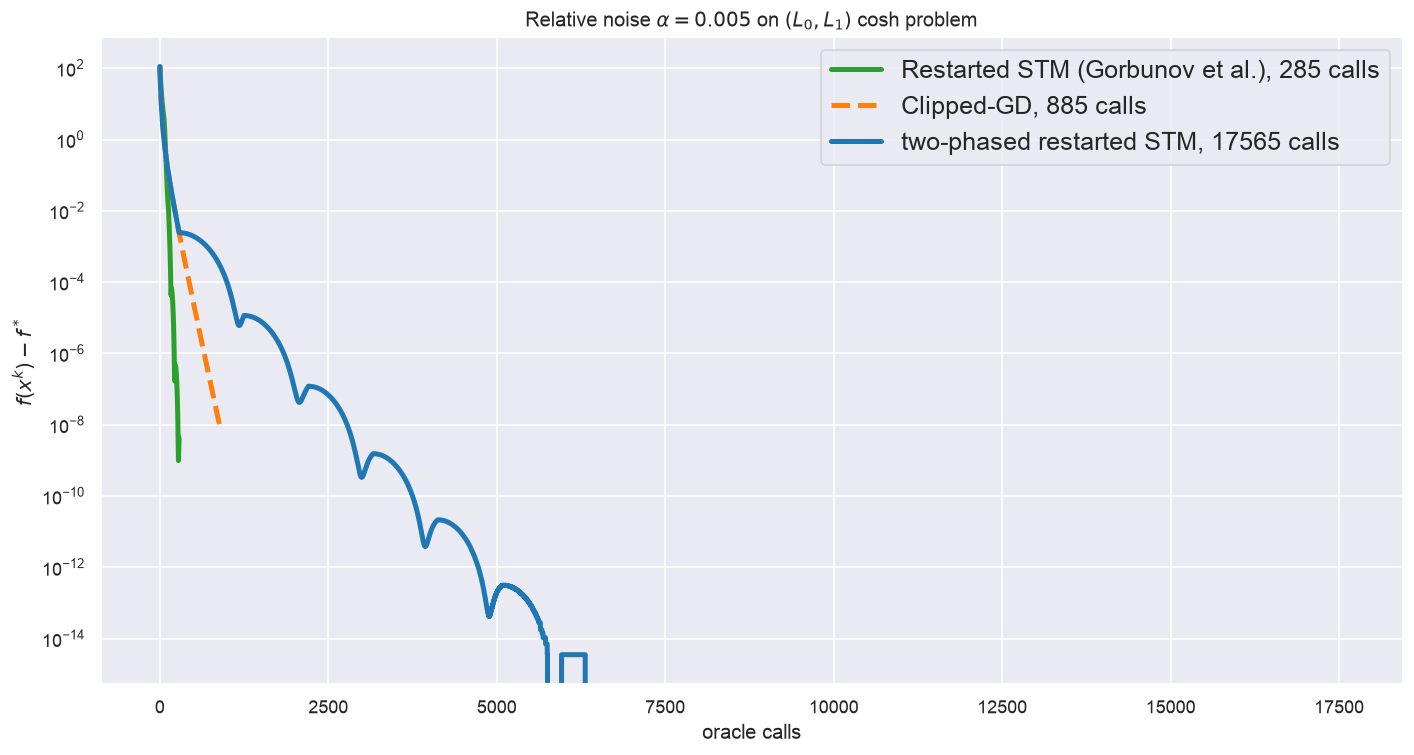

native=285, two-phase=17565, clipped-GD=885, confinement R/R0=0.99


In [ ]:
# E5: native restarted STM, two-phase method, and clipped-GD under relative noise
prob = make_sc_cosh(d=20, kappa_cond=50.0)
x0 = np.full(20, 0.6)
alpha = 0.005
eps = 1e-8
max_relative_calls = 600000
dirs = random_unit_sequence(max_relative_calls + 1, 20, 601)

g_nat, c_nat, Ns_nat, maxR = native_restart_stm(prob, x0, alpha, eps, dirs)
g_tp = two_phase(prob, x0, alpha, eps, dirs)
g_gd = clipped_gd_relative_trace(prob, x0, alpha, eps, N=max_relative_calls, dirs=dirs)

with sns.plotting_context("notebook"), sns.axes_style("darkgrid"):
    plt.figure(figsize=(14, 7), dpi=120)
    plt.semilogy(np.arange(len(g_nat)), g_nat, linewidth=3.0, color="C2", label=fr"Restarted STM (Gorbunov et al.), {c_nat} calls")
    plt.semilogy(np.arange(len(g_gd)), g_gd, "--", linewidth=3.0, color="C1", label=fr"Clipped-GD, {len(g_gd)-1} calls")
    plt.semilogy(np.arange(len(g_tp)), g_tp, linewidth=3.0, color="C0", label=fr"two-phased restarted STM, {len(g_tp)-1} calls")
    plt.xlabel("oracle calls")
    plt.ylabel(r"$f(x^k)-f^*$")
    plt.title(r"Relative noise $\alpha=0.005$ on $(L_0,L_1)$ cosh problem")
    plt.legend(fontsize=15, loc="upper right")
    plt.show()

print(f"native={c_nat}, two-phase={len(g_tp)-1}, clipped-GD={len(g_gd)-1}, confinement R/R0={maxR:.2f}")


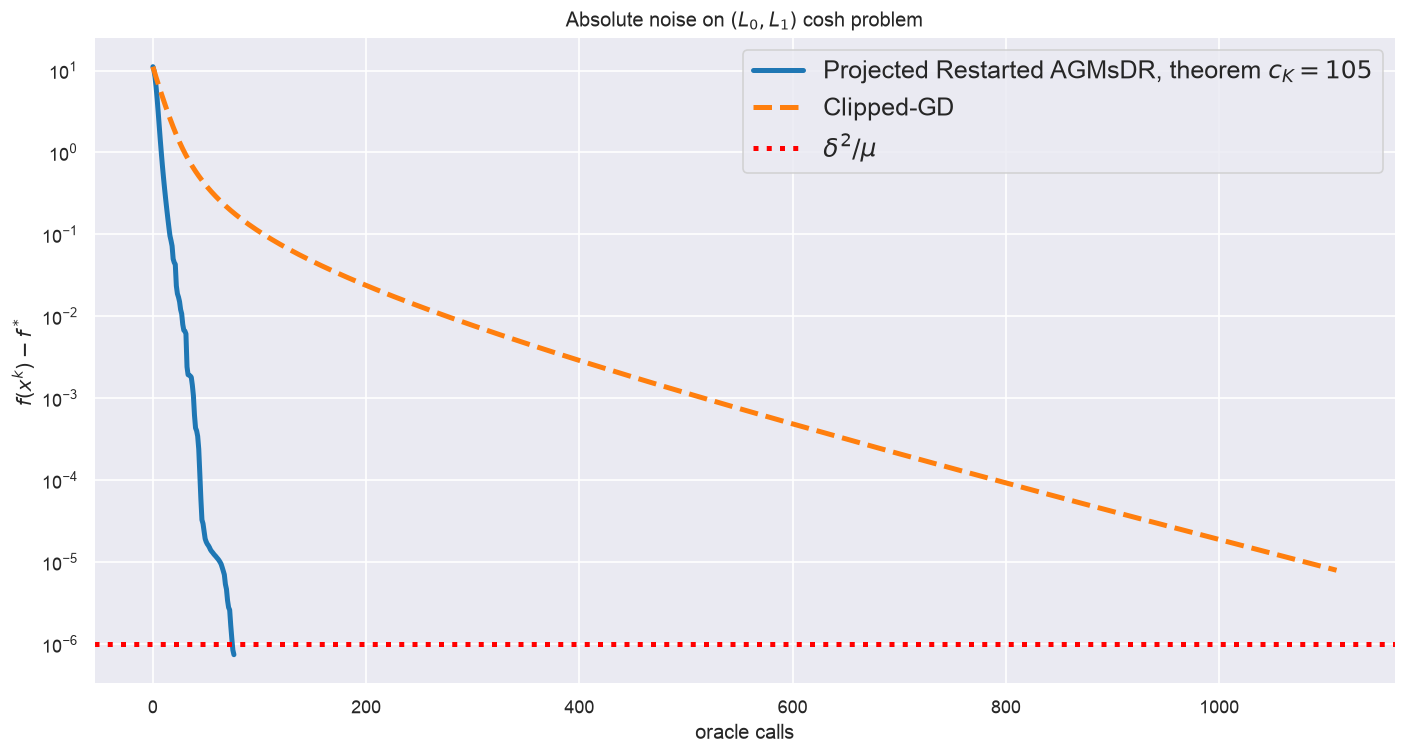

AGMsDR calls=76, Clipped-GD calls=1110, floor=1.00e-06


In [ ]:
# E6: thresholded projected AGMsDR under absolute noise
prob = make_sc_cosh(d=20, kappa_cond=100.0)
x0 = np.full(20, 0.20)
delta_abs = 1e-3
K_abs = 4.0
c_R_abs = 3.0
max_absolute_calls = 200000
dirs = random_unit_sequence(max_absolute_calls + 1, 20, 701)
c_K_abs, C_st_abs, eps_coef_abs = agmsdr_constants(K_abs, c_R_abs)
eps_abs = eps_coef_abs * delta_abs ** 2 / prob.mu

g_agmsdr = synthetic_agmsdr_restarted(prob, x0, K_abs, delta_abs, c_R_abs, c_K_abs, eps_abs, dirs)
g_gd = clipped_gd_abs(prob, x0, delta_abs, K_abs, N=max_absolute_calls, dirs=dirs)
floor = delta_abs ** 2 / prob.mu

with sns.plotting_context("notebook"), sns.axes_style("darkgrid"):
    plt.figure(figsize=(14, 7), dpi=120)
    plt.semilogy(np.arange(len(g_agmsdr)), g_agmsdr, linewidth=3.0, color="C0", label=fr"Projected Restarted AGMsDR, theorem $c_K={c_K_abs:.0f}$")
    plt.semilogy(np.arange(len(g_gd)), g_gd, "--", linewidth=3.0, color="C1", label="Clipped-GD")
    plt.axhline(floor, color="red", linestyle=":", linewidth=3.0, label=r"$\delta^2/\mu$")
    plt.xlabel("oracle calls")
    plt.ylabel(r"$f(x^k)-f^*$")
    plt.title(r"Absolute noise on $(L_0,L_1)$ cosh problem")
    plt.legend(fontsize=15)
    plt.show()

print(f"AGMsDR calls={len(g_agmsdr)-1}, Clipped-GD calls={len(g_gd)-1}, floor={floor:.2e}")
